In [1]:
#Write a program to generate following noises using equations derived 
#from PDFs of noise distributions. Compare your output with those 
#generated using inbuilt function imnoise. Plot the histograms of generated 
#noise to determine the shape of the distribution.  
#1. Uniform noise  
#2. Gaussian noise  
#3. Erlang noise  
#4. Exponential noise  
#5. Rayleigh noise 
%pip install numpy matplotlib opencv-python

Note: you may need to restart the kernel to use updated packages.


<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
C:\Users\saraj\AppData\Local\Temp\ipykernel_2400\2146035442.py:6: SyntaxWarning: invalid escape sequence '\d'
  img = cv2.imread("D:\doll.jpg", cv2.IMREAD_GRAYSCALE)


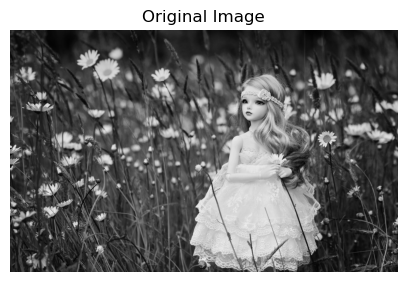

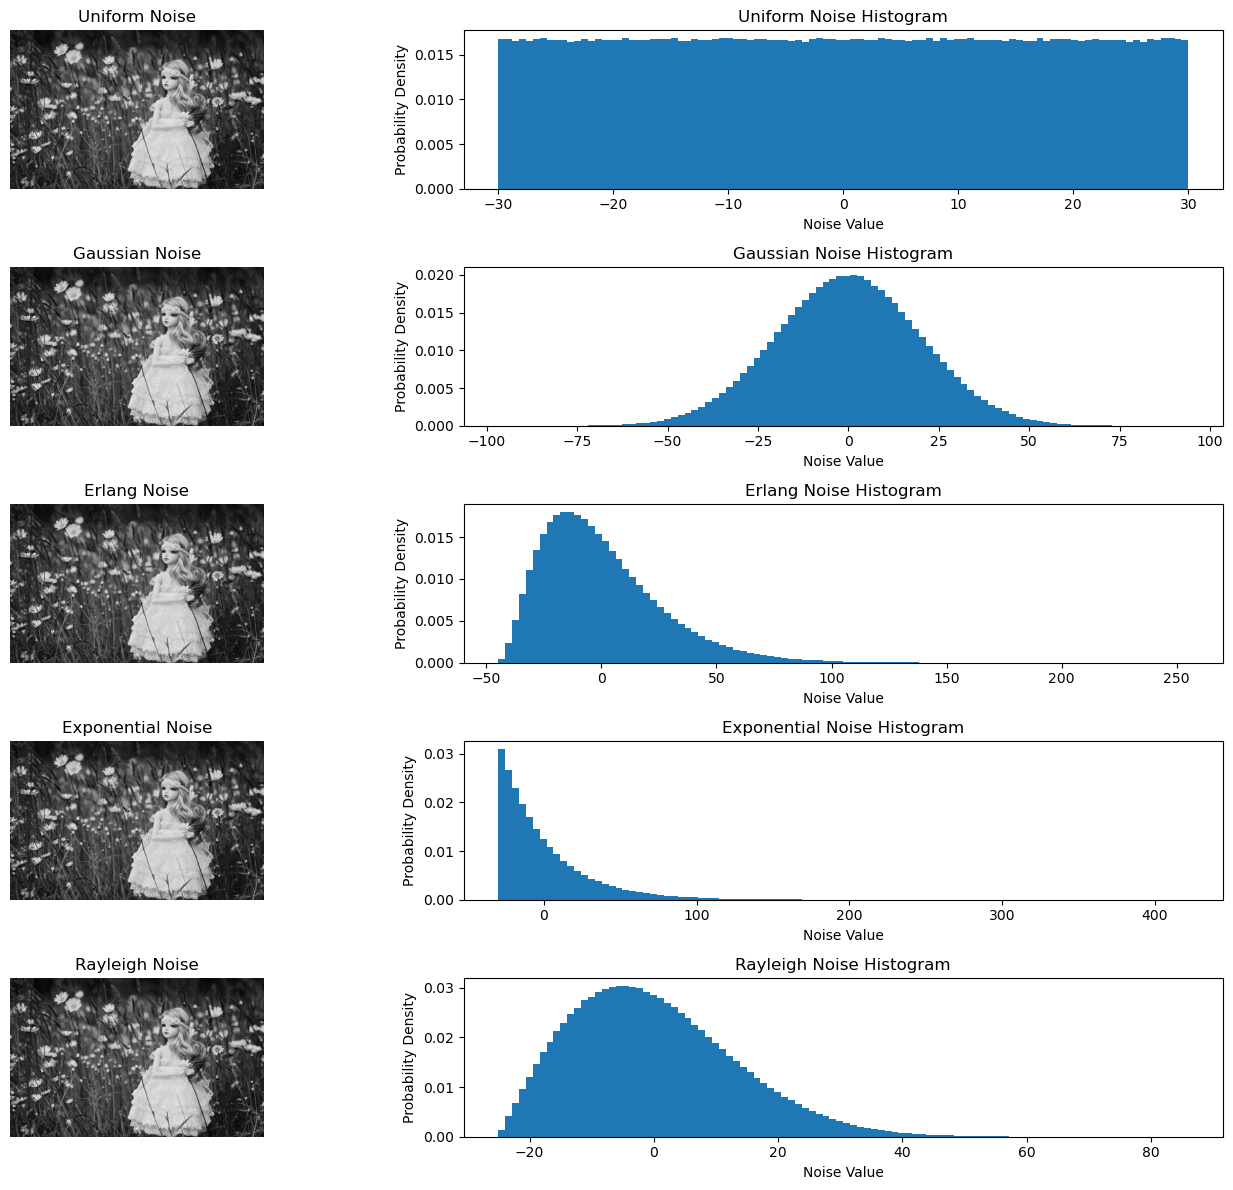

All five noise distributions generated successfully.
Noisy images and histograms saved/displayed.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

img = cv2.imread("D:\doll.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Please place input.jpg in the same folder.")

M, N = img.shape

size = M * N
np.random.seed(42)

a, b = -30, 30
uniform = np.random.uniform(a, b, size)
mu = 0
sigma = 20

u1 = np.random.uniform(0, 1, size)
u2 = np.random.uniform(0, 1, size)

gaussian = mu + sigma * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)

k = 3
lam = 1 / 15

erlang = np.zeros(size)

for i in range(k):
    u = np.random.uniform(0, 1, size)
    erlang += -np.log(u) / lam

lam_exp = 1 / 30

u = np.random.uniform(0, 1, size)
exponential = -np.log(u) / lam_exp

rayleigh_sigma = 20

u = np.random.uniform(0, 1, size)
rayleigh = rayleigh_sigma * np.sqrt(-2 * np.log(u))

noise_list = [
    uniform,
    gaussian,
    erlang,
    exponential,
    rayleigh
]

noise_names = [
    "Uniform Noise",
    "Gaussian Noise",
    "Erlang Noise",
    "Exponential Noise",
    "Rayleigh Noise"
]
plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()
plt.figure(figsize=(15, 12))

for i in range(5):
    noise = noise_list[i].reshape(M, N)

    if i >= 2:
        noise = noise - np.mean(noise)

    noisy_img = img.astype(float) + noise
    noisy_img = np.clip(noisy_img, 0, 255).astype(np.uint8)

    plt.subplot(5, 2, 2*i + 1)
    plt.imshow(noisy_img, cmap="gray")
    plt.title(noise_names[i])
    plt.axis("off")
    plt.subplot(5, 2, 2*i + 2)
    plt.hist(noise.flatten(), bins=100, density=True)
    plt.title(noise_names[i] + " Histogram")
    plt.xlabel("Noise Value")
    plt.ylabel("Probability Density")

    filename = noise_names[i].lower().replace(" ", "_") + ".jpg"
    cv2.imwrite(filename, noisy_img)

plt.tight_layout()
plt.show()

print("All five noise distributions generated successfully.")
print("Noisy images and histograms saved/displayed.")